# XGBoost for regression

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train XGBoost to predict the rent price of an apartment. We train with early stopping, then we compare the approximate and the histogram split finding algorithms, the missing values left as they are against the missing values filled, and we look at how the regularization parameters `gamma` and `lambda` change the trees. Then, we use callbacks, one of which saves checkpoints during the training, we save and load the model, and we resume the training from a checkpoint. Finally, we compare the three types of feature importance.

XGBoost also ships a scikit-learn wrapper, `XGBRegressor` and `XGBClassifier`, which fits into scikit-learn pipelines and searches. In this course we use the native API, `xgb.train` with a `DMatrix`, because it exposes the full feature set of the library.

In [1]:
import pathlib
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

### Load data

We use the apartment rent data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/apartment_rent.csv", index_col="time")
df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,housing/rent/apartment,1.0,1.0,No,Thumbnail,Not specified,1191.0,800.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,housing/rent/apartment,2.0,4.0,No,Yes,Not specified,1450.0,1880.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1395.0,1661.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1255.0,1400.0,Orange Park,FL,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,housing/rent/apartment,2.0,2.0,No,Yes,Not specified,1693.0,1346.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0


In [3]:
# XGBoost splits on categories directly, so we keep them as pandas categories instead of integers
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].astype("category")

# XGBoost takes missing values, so we leave NaN as it is

df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,housing/rent/apartment,1.0,1.0,No,Thumbnail,Not specified,1191.0,800.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,housing/rent/apartment,2.0,4.0,No,Yes,Not specified,1450.0,1880.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1395.0,1661.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1255.0,1400.0,Orange Park,FL,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,housing/rent/apartment,2.0,2.0,No,Yes,Not specified,1693.0,1346.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="price"),
    df["price"],
    test_size=0.3,
    random_state=0,
)

X_train.shape, X_test.shape

((69872, 39), (29946, 39))

In [5]:
# the mean rent price
y_train.mean(), y_test.mean()

(np.float64(1527.515742929929), np.float64(1526.5632805716957))

### Build the data containers

The native API takes its data in a `DMatrix`. We build each one once and reuse it in every model of the notebook.

In [6]:
dtrain = xgb.DMatrix(X_train, label=y_train, enable_categorical=True)
dtest = xgb.DMatrix(X_test, label=y_test, enable_categorical=True)

dtrain.num_row(), dtest.num_row()

(69872, 29946)

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on.

In [7]:
params = {
    # learning task
    "objective": "reg:squarederror",
    "eval_metric": "rmse",

    # tree structure and algorithm
    "booster": "gbtree",
    "tree_method": "hist",
    "eta": 0.3,                    # the learning rate
    "grow_policy": "depthwise",
    "max_bin": 256,
    "max_depth": 6,
    "max_leaves": 0,               # 0 means no limit
    "min_child_weight": 1,

    # regularization
    "gamma": 0,
    "lambda": 1,
    "alpha": 0,

    # sampling
    "subsample": 1,
    "sampling_method": "uniform",
    "colsample_bytree": 1,
    "colsample_bylevel": 1,
    "colsample_bynode": 1,

    # categorical features
    "max_cat_to_onehot": 4,
    "max_cat_threshold": 64,

    # hardware and reproducibility
    "device": "cpu",
    "nthread": 4,                  # fixed, so that the timings are comparable
    "seed": 0,
}

We let XGBoost add up to 2000 trees, and we stop when the rmse in the test set has not improved for 50 rounds. Here, to keep the notebook short, the test set plays the role of the validation set. In a real project, we would hold out a separate validation set, because choosing the number of trees on the test set makes the test score optimistic.

In [8]:
evals_result = {}

booster = xgb.train(
    params,
    dtrain,
    num_boost_round=2000,
    evals=[(dtrain, "train"), (dtest, "test")],
    early_stopping_rounds=50,
    evals_result=evals_result,
    verbose_eval=100,
)

[0]	train-rmse:736.09868	test-rmse:714.64695


[100]	train-rmse:217.87119	test-rmse:473.00414


[200]	train-rmse:180.60570	test-rmse:467.39545


[300]	train-rmse:159.61362	test-rmse:465.87587


[400]	train-rmse:146.16287	test-rmse:465.21978


[433]	train-rmse:142.12382	test-rmse:465.41892


In [9]:
# best_iteration counts from 0, so the best model has one tree more
num_rounds = booster.best_iteration + 1

print(f"best number of trees: {num_rounds}, trees in the booster: {booster.num_boosted_rounds()}")

best number of trees: 384, trees in the booster: 434


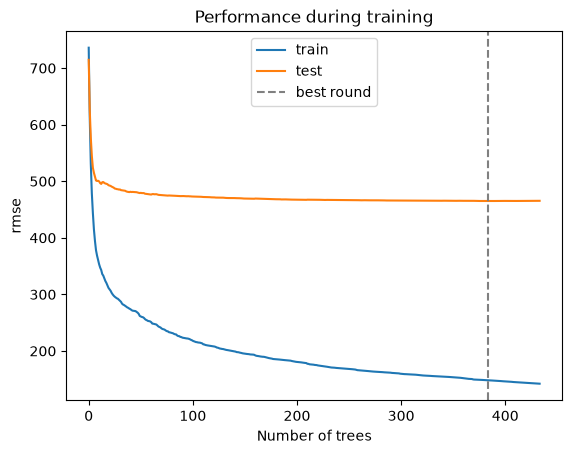

In [10]:
plt.plot(evals_result["train"]["rmse"], label="train")
plt.plot(evals_result["test"]["rmse"], label="test")
plt.axvline(booster.best_iteration, color="grey", linestyle="dashed", label="best round")
plt.xlabel("Number of trees")
plt.ylabel("rmse")
plt.title("Performance during training")
plt.legend()
plt.show()

The test rmse reached its best value with 384 trees, and early stopping waited 50 more rounds before it gave up, so the booster holds 434 trees.

XGBoost keeps the trees that it trained after the best round, and `predict` uses all of them by default, while the scikit-learn wrapper, LightGBM and CatBoost all stop at the best round by themselves, so here we cut the booster ourselves.

In [11]:
# keep only the trees up to the best round
booster = booster[:booster.best_iteration + 1]

booster.num_boosted_rounds()

384

In [12]:
def evaluate(model, dtrain, y_train, dtest, y_test):
    for name, data, y in [("train", dtrain, y_train), ("test", dtest, y_test)]:
        predictions = model.predict(data)
        rmse = root_mean_squared_error(y, predictions)
        r2 = r2_score(y, predictions)
        print(f"{name} rmse: {rmse:.2f}, r2: {r2:.4f}")


evaluate(booster, dtrain, y_train, dtest, y_test)

train rmse: 148.19, r2: 0.9739


test rmse: 465.02, r2: 0.7140


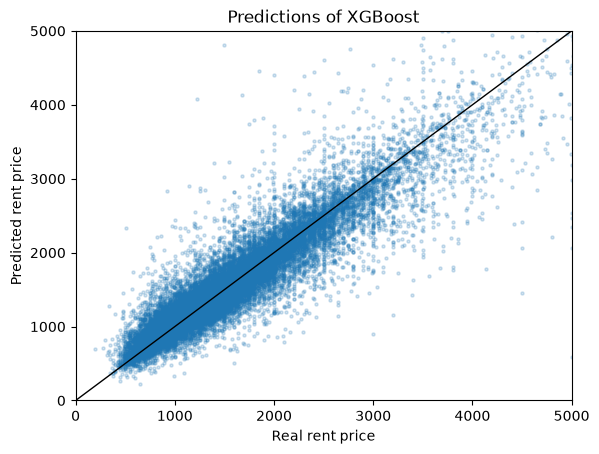

In [13]:
# Let's plot the predictions vs the true rent
# We zoom into the most common prices, because a few apartments cost more than 30000
predictions = booster.predict(dtest)

plt.scatter(y_test, predictions, alpha=0.2, s=5)
plt.plot([0, 5000], [0, 5000], color="black", linewidth=1)
plt.xlim(0, 5000)
plt.ylim(0, 5000)
plt.xlabel("Real rent price")
plt.ylabel("Predicted rent price")
plt.title("Predictions of XGBoost")
plt.show()

The model fits the train set much better than the test set, with an rmse of 148 against 465, and its test error is higher than the one of the gradient boosting machine of the previous section.

Let's now change one hyperparameter at a time to understand what is going on.

Below, we train every setting for the number of trees that early stopping found, so that differences in time come from the setting and not from the number of trees.

In [14]:
def timed_train(params, dtrain, num_boost_round):
    start = time.perf_counter()
    model = xgb.train(params, dtrain, num_boost_round)
    return model, time.perf_counter() - start

In [15]:
def test_scores(model, dtest, y_test):
    predictions = model.predict(dtest)
    return {
        "rmse": root_mean_squared_error(y_test, predictions),
        "r2": r2_score(y_test, predictions),
    }

### Split finding algorithms

We saw in the lectures on split finding and the weighted quantile sketch that the approximate algorithm computes the gain only at a few candidate thresholds, placed at weighted quantiles of the Hessians and proposed again before each tree. At the end of the lecture on the weighted quantile sketch, we also mentioned the histogram method, today's default, which picks its candidates only once, before training, and does not weight them. We compare the two.

The times depend on the machine, so we should read them relative to each other.

In [16]:
results = {}
for tree_method in ["approx", "hist"]:
    model, seconds = timed_train({**params, "tree_method": tree_method}, dtrain, num_rounds)
    results[tree_method] = {**test_scores(model, dtest, y_test), "seconds": seconds}

pd.DataFrame(results).T.round(4)

,rmse,r2,seconds
approx,465.0223,0.714,11.0888
hist,465.0223,0.714,9.5581


The two methods return exactly the same model here. With squared error every Hessian is 1, so the weighted candidates of the approximate method are the plain quantiles of the features, the same before every tree, and they match the bins of the histogram method. The histogram method is also a little faster, 9.6 against 11.1 seconds here.

### Missing values

We saw in the lecture on sparsity-aware split finding that every split learns a default direction for the missing values. In that lecture, we also mentioned a simple alternative, filling them with a value outside the distribution, which puts all of them on one side of every split.

To compare the two, we fill every missing value with -1 and train on it next to the data where the missing values are left to XGBoost. In the apartment data, less than 0.3% of the values are missing in each variable, in a few numerical variables and in `cityname` and `state`.

In [17]:
# we replace NaN by a value outside the distribution, before the categories are set
df_filled = pd.read_csv("../prepare-data/apartment_rent.csv", index_col="time").fillna(-1)
df_filled[categorical_vars] = df_filled[categorical_vars].astype(str).astype("category")

In [18]:
# the same split as before, so the filled data has the same rows in train and test
X_train_filled, X_test_filled, _, _ = train_test_split(
    df_filled.drop(columns="price"),
    df_filled["price"],
    test_size=0.3,
    random_state=0,
)

In [19]:
dtrain_filled = xgb.DMatrix(X_train_filled, label=y_train, enable_categorical=True)
dtest_filled = xgb.DMatrix(X_test_filled, label=y_test, enable_categorical=True)

In [20]:
settings = {
    "nothing filled": (dtrain, dtest),
    "everything filled with -1": (dtrain_filled, dtest_filled),
}

results = {}
for name, (train_data, test_data) in settings.items():
    model = xgb.train(params, train_data, num_rounds)
    results[name] = test_scores(model, test_data, y_test)

pd.DataFrame(results).T.round(4)

,rmse,r2
nothing filled,465.0223,0.7140
everything filled with -1,476.5811,0.6996


Filling every missing value raises the test rmse from 465 to 477. With so few values missing, part of the difference probably comes from training a slightly different model, but the direction agrees with what we saw in the lecture: with -1, the apartments with a missing value always go to the side where -1 falls, while the default direction sends them to the side where their prices fit best.

### Regularization with gamma and lambda

In the lecture on the regularized objective, we added two penalties to every tree. The parameter `gamma` is subtracted from the gain of every split, so a split is only made when its gain is larger than `gamma`. The parameter `lambda` is added to the Hessian sum in the leaf values and in the gain, so it shrinks the leaf values.

With squared error, the gradient of an apartment is its error in dollars and its Hessian is 1, so the gain of a split grows with the square of those errors and with the number of apartments in the node. We should therefore expect values of `gamma` up to 100 to be small next to most gains.

Next to the rmse, we record the mean number of leaves per tree for `gamma` and the mean absolute leaf weight for `lambda`.

In [21]:
def mean_leaves(model):
    trees = model.trees_to_dataframe()
    return trees[trees["Feature"] == "Leaf"].groupby("Tree").size().mean()


def mean_abs_weight(model):
    # in the rows of the leaves, the column Gain holds the leaf weight
    trees = model.trees_to_dataframe()
    return trees.loc[trees["Feature"] == "Leaf", "Gain"].abs().mean()

In [22]:
def sweep(param, values, column, summary):
    results = {}
    for value in values:
        model = xgb.train({**params, param: value}, dtrain, num_rounds)
        results[value] = {
            "train rmse": root_mean_squared_error(y_train, model.predict(dtrain)),
            "test rmse": root_mean_squared_error(y_test, model.predict(dtest)),
            column: summary(model),
        }
    return pd.DataFrame(results).T

In [23]:
def plot_sweep(results, param, column):
    # the values are far apart, so we place them at equal distances
    positions = range(len(results))
    plt.plot(positions, results["train rmse"], marker="o", label="train rmse")
    plt.plot(positions, results["test rmse"], marker="o", label="test rmse")
    plt.xticks(positions, results.index)
    plt.xlabel(param)
    plt.ylabel("rmse")
    plt.legend(loc="center left")
    plt.twinx()
    plt.plot(positions, results[column], marker="o", color="grey", linestyle="dashed")
    plt.ylabel(f"{column} (dashed)")
    plt.title(f"Effect of {param}")
    plt.show()

In [24]:
gamma_results = sweep("gamma", [0, 1, 10, 50, 100], "leaves per tree", mean_leaves)

gamma_results.round(1)

,train rmse,test rmse,leaves per tree
0,148.2,465.0,55.1
1,148.1,465.3,55.1
10,147.6,465.6,54.7
50,145.0,464.9,54.9
100,149.7,464.6,54.8


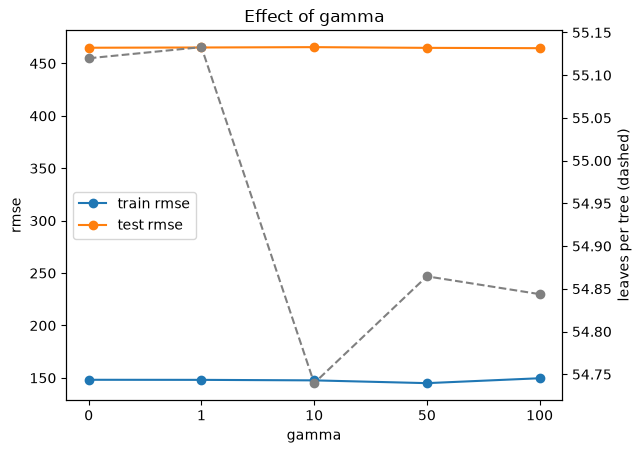

In [25]:
plot_sweep(gamma_results, "gamma", "leaves per tree")

As we expected, `gamma` up to 100 changes almost nothing. The leaves per tree stay around 55 and the test rmse stays at about 465, so on this data `gamma` would need values in the thousands before it removed many splits.

In [26]:
lambda_results = sweep("lambda", [0, 1, 10, 50, 100], "mean abs leaf weight", mean_abs_weight)

lambda_results.round(1)

,train rmse,test rmse,mean abs leaf weight
0,140.2,448.5,65.8
1,148.2,465.0,42.5
10,178.0,477.9,26.5
50,230.4,484.6,22.0
100,259.4,440.5,16.1


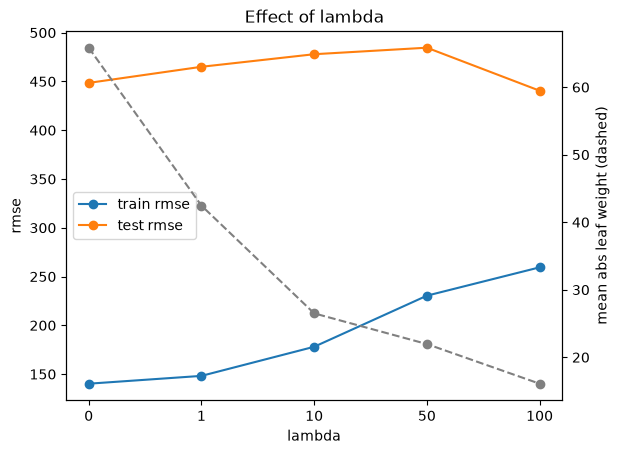

In [27]:
plot_sweep(lambda_results, "lambda", "mean abs leaf weight")

As `lambda` grows, the mean absolute leaf weight shrinks steadily, from about 66 to 16 dollars, so each tree corrects less of the error, and the train rmse rises from 140 to 259.

The test rmse does not follow a clear direction: it goes up until 50 and then drops to the lowest value of the table at 100. So `lambda` closes part of the gap between train and test, but the test error is sensitive to the value that we pick.

## Callbacks and model IO

In this part, we use callbacks during the training, we save and load the model, and we resume the training from a checkpoint.

### Callbacks

A callback is an object that XGBoost calls after every round. Early stopping and the log of every round are built-in callbacks too, `EarlyStopping` and `EvaluationMonitor`, which `xgb.train` adds for us.

Here, we write one that prints the test rmse every 100 rounds, and we combine it with two more built-in callbacks: `LearningRateScheduler`, which sets the learning rate of each round from a function, and `TrainingCheckPoint`, which saves the model every 50 rounds.

We train with the same early stopping as before, so the run stops by itself, and we cut the booster to its best round, as we did for our booster.

In [28]:
class PrintEvery(xgb.callback.TrainingCallback):
    def __init__(self, period):
        self.period = period

    def after_iteration(self, model, epoch, evals_log):
        if epoch % self.period == 0:
            print(f"round {epoch}: test rmse {evals_log['test']['rmse'][-1]:.2f}")
        # returning True would stop the training
        return False

In [29]:
def decay(epoch):
    return 0.3 * 0.99 ** epoch


# TrainingCheckPoint does not create the folder, and we remove the files of an earlier run
checkpoints = pathlib.Path("checkpoints") / "regression"
checkpoints.mkdir(parents=True, exist_ok=True)
for path in checkpoints.glob("*.ubj"):
    path.unlink()

In [30]:
scheduled = xgb.train(
    params,
    dtrain,
    num_boost_round=2000,
    evals=[(dtrain, "train"), (dtest, "test")],
    early_stopping_rounds=50,
    verbose_eval=False,
    callbacks=[
        PrintEvery(100),
        xgb.callback.LearningRateScheduler(decay),
        xgb.callback.TrainingCheckPoint(directory=checkpoints, name="checkpoint", interval=50),
    ],
)

round 0: test rmse 714.65


round 100: test rmse 469.58


round 200: test rmse 465.58


round 300: test rmse 464.28


round 400: test rmse 463.92


...

round 700: test rmse 463.73


round 800: test rmse 463.72


round 900: test rmse 463.72


round 1000: test rmse 463.72


round 1100: test rmse 463.72


In [31]:
print(f"best number of trees: {scheduled.best_iteration + 1}, trees in the booster: {scheduled.num_boosted_rounds()}")

# keep only the trees up to the best round, as for our booster
scheduled = scheduled[:scheduled.best_iteration + 1]

evaluate(scheduled, dtrain, y_train, dtest, y_test)

best number of trees: 1061, trees in the booster: 1111


train rmse: 219.72, r2: 0.9427


test rmse: 463.72, r2: 0.7156


With the learning rate shrinking, the later trees add less and less, so early stopping finds the best round much later, at 1061 trees against 384 for our booster. The test rmse ends a little below the one of our booster, 463.72 against 465.02, while the train rmse is much higher, 219.72 against 148.19, so the schedule gives a model that overfits less.

The number in the file name is the index of the round, which counts from 0, so `checkpoint_50.ubj` holds 51 trees.

In [32]:
# sort by round number, not alphabetically
[path.name for path in sorted(checkpoints.iterdir(), key=lambda path: int(path.stem.split("_")[1]))]

['checkpoint_50.ubj',
 'checkpoint_100.ubj',
 'checkpoint_150.ubj',
 'checkpoint_200.ubj',
 'checkpoint_250.ubj',
 'checkpoint_300.ubj',
 'checkpoint_350.ubj',
 'checkpoint_400.ubj',
 'checkpoint_450.ubj',
 'checkpoint_500.ubj',
 'checkpoint_550.ubj',
 'checkpoint_600.ubj',
 'checkpoint_650.ubj',
 'checkpoint_700.ubj',
 'checkpoint_750.ubj',
 'checkpoint_800.ubj',
 'checkpoint_850.ubj',
 'checkpoint_900.ubj',
 'checkpoint_950.ubj',
 'checkpoint_1000.ubj',
 'checkpoint_1050.ubj',
 'checkpoint_1100.ubj']

### Save and load the model

We save the model in XGBoost's binary UBJSON format, which later versions of the library can still read, and we load it into a new booster.

In [33]:
booster.save_model("xgboost-regression.ubj")
loaded = xgb.Booster(model_file="xgboost-regression.ubj")

np.array_equal(booster.predict(dtest), loaded.predict(dtest))

True

### Continue the training

Say that the training with the callbacks had been interrupted shortly after round 50. Then its last checkpoint is `checkpoint_50.ubj`, and we do not need to start again: we load the checkpoint, pass it to `xgb_model`, and XGBoost adds new trees on top of the ones that it already has. We add 100 trees with a smaller learning rate.

In [34]:
loaded = xgb.Booster(model_file=checkpoints / "checkpoint_50.ubj")

loaded.num_boosted_rounds()

51

In [35]:
continued = xgb.train(
    {**params, "eta": 0.05},
    dtrain,
    num_boost_round=100,
    evals=[(dtest, "test")],
    verbose_eval=25,
    xgb_model=loaded,
)

print(f"trees before: {loaded.num_boosted_rounds()}, trees after: {continued.num_boosted_rounds()}")

[0]	test-rmse:475.68742


[25]	test-rmse:474.47198


[50]	test-rmse:473.73637


[75]	test-rmse:472.41882


[99]	test-rmse:471.53445


trees before: 51, trees after: 151


In [36]:
evaluate(continued, dtrain, y_train, dtest, y_test)

train rmse: 250.85, r2: 0.9253

test rmse: 471.53, r2: 0.7059


Starting from the 51 trees of the checkpoint, the 100 new trees with a learning rate of 0.05 bring the test rmse down slowly, to 471.53, which is still above the 465.02 of our booster with its 384 trees.

## Feature importance

We saw in the lecture on feature importance that XGBoost builds three summaries for every feature from its splits: weight, gain and cover. We plot each type separately, with the 15 most important features.

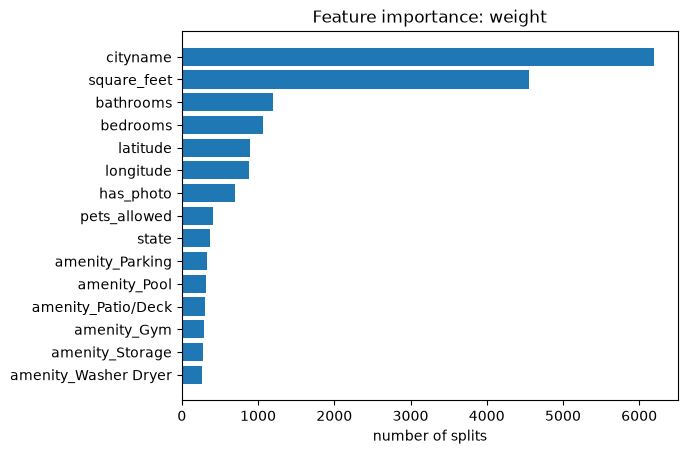

In [37]:
weight = pd.Series(booster.get_score(importance_type="weight")).sort_values(ascending=False)

# the 15 most important features, the most important on top
top = weight.head(15)
plt.barh(top.index[::-1], top.values[::-1])
plt.xlabel("number of splits")
plt.title("Feature importance: weight")
plt.show()

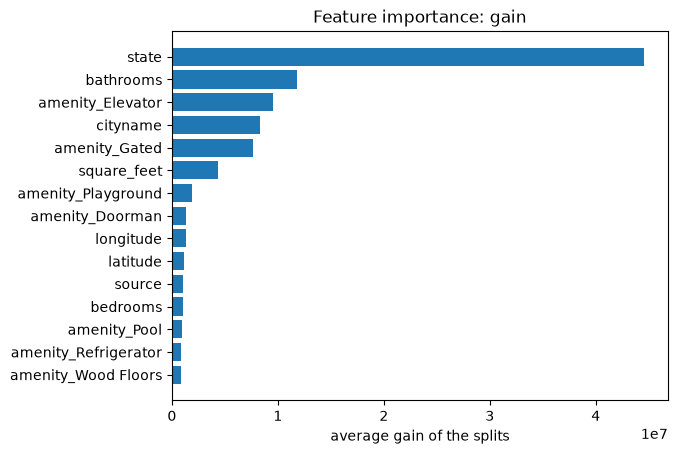

In [38]:
gain = pd.Series(booster.get_score(importance_type="gain")).sort_values(ascending=False)

# the 15 most important features, the most important on top
top = gain.head(15)
plt.barh(top.index[::-1], top.values[::-1])
plt.xlabel("average gain of the splits")
plt.title("Feature importance: gain")
plt.show()

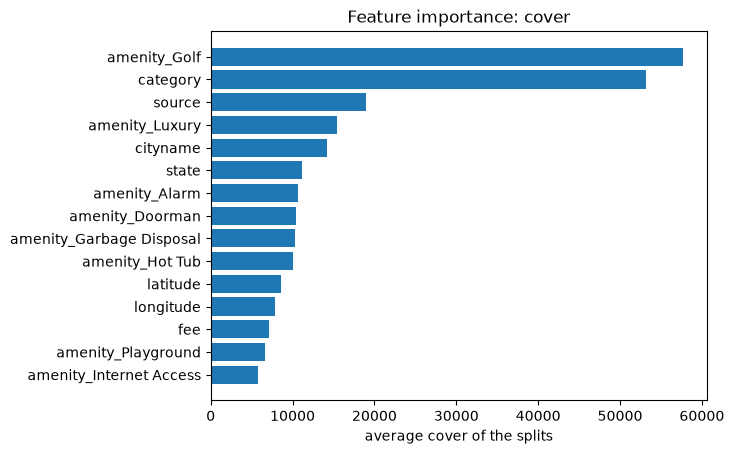

In [39]:
cover = pd.Series(booster.get_score(importance_type="cover")).sort_values(ascending=False)

# the 15 most important features, the most important on top
top = cover.head(15)
plt.barh(top.index[::-1], top.values[::-1])
plt.xlabel("average cover of the splits")
plt.title("Feature importance: cover")
plt.show()

The three charts disagree. By weight, `cityname` and `square_feet` come first, with many more splits than any other feature, because variables with many values or categories offer many places to split. By gain, `state` comes first by far, followed by `bathrooms`, and some amenities such as `amenity_Elevator` rank high from a few splits with a large gain. By cover, rare variables such as `amenity_Golf` and `category` come first, because with squared error the cover is the number of apartments, and their few splits are reached by many of them.